# Exploring the U.S. Data Analyst Job Market

## Project overview

This notebook introduces the job-postings dataset through a focused exploratory analysis of Data Analyst roles in the United States. The goal is to understand where opportunities are concentrated, which benefits or requirements appear in postings, and which employers advertise the most roles.

## Questions explored

1. Which U.S. locations have the most Data Analyst job postings?
2. How often do postings mention remote work, degree requirements, or health insurance?
3. Which companies list the largest number of Data Analyst openings?

## Load and prepare the data

Import the analysis libraries, load the job-postings dataset, and convert the date and skills fields into analysis-ready formats.

In [48]:
# Importing Libraries
import ast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

## Define the analysis scope

Limit the dataset to postings classified as **Data Analyst** roles in the **United States**, then apply a consistent visual theme for the charts.

In [49]:
# Only get data analyst jobs
df_DA_US = df[
	(df["job_title_short"] == "Data Analyst") & (df["job_country"] == "United States")
].copy()

# Set Theme
sns.set_theme(style="ticks", font_scale=1.2)

### Leading job locations

Compare the ten locations with the highest number of U.S. Data Analyst postings.

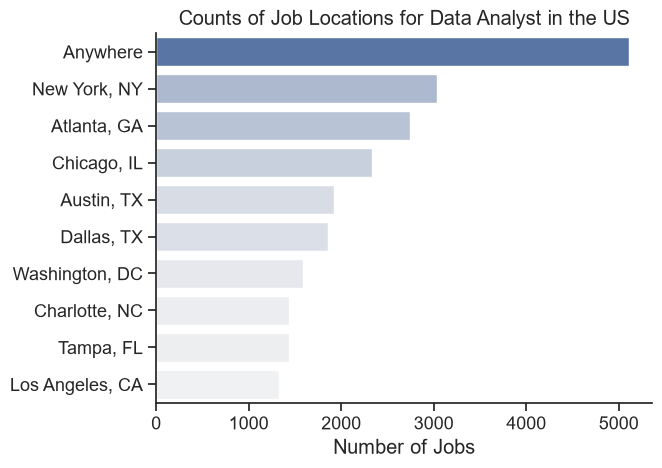

In [50]:
df_plot = df_DA_US["job_location"].value_counts().head(10).to_frame()

sns.barplot(data=df_plot, x="count", y="job_location", hue="count", palette="light:b", legend=False)
sns.despine()

plt.title("Counts of Job Locations for Data Analyst in the US")
plt.xlabel("Number of Jobs")
plt.ylabel("")
plt.show()

### Common posting characteristics

Review the share of postings that offer remote work, omit a degree requirement, or mention health insurance.

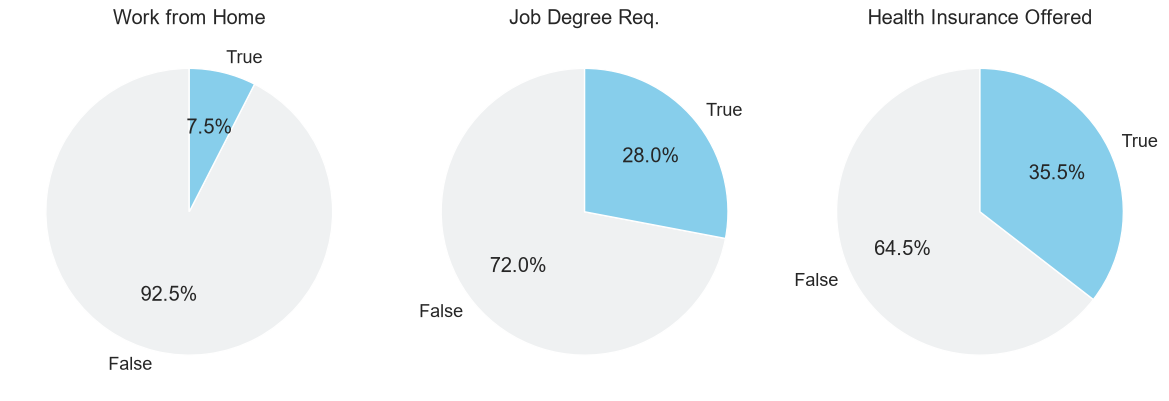

In [51]:
colors = sns.light_palette("skyblue", n_colors=2)

fig, ax = plt.subplots(1, 3, figsize=(12, 5))

dict_column = {
	"job_work_from_home": "Work from Home",
	"job_no_degree_mention": "Job Degree Req.",
	"job_health_insurance": "Health Insurance Offered",
}

for i, (col, title) in enumerate(dict_column.items()):
	counts = df_DA_US[col].value_counts().reindex([False, True], fill_value=0)

	ax[i].pie(
		counts,
		startangle=90,
		autopct="%1.1f%%",
		labels=["False", "True"],
		colors=colors,
	)
	ax[i].set_title(title)

fig.tight_layout()
plt.show()

### Companies with the most openings

Rank the ten employers with the largest number of Data Analyst postings in the filtered dataset.

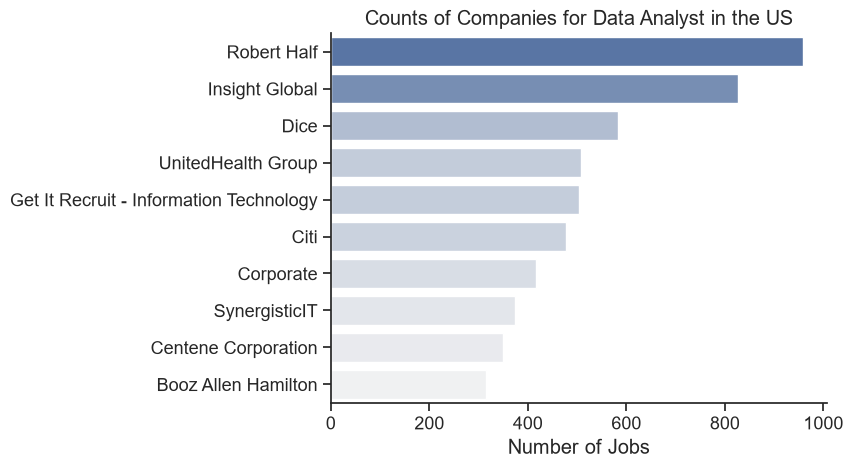

In [40]:
df_plot = df_DA_US["company_name"].value_counts().head(10).to_frame()

sns.barplot(data=df_plot, x="count", y="company_name", hue="count", palette="light:b", legend=False)
sns.despine()

plt.title("Counts of Companies for Data Analyst in the US")
plt.xlabel("Number of Jobs")
plt.ylabel("")
plt.show()